
Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Actual vs Predicted:
   actual  predicted
0       0          0
1       2          2
2       1          1
3       1          1
4       0          0
5       1          1
6       0          0
7       0          0
8       2          2
9       1          1


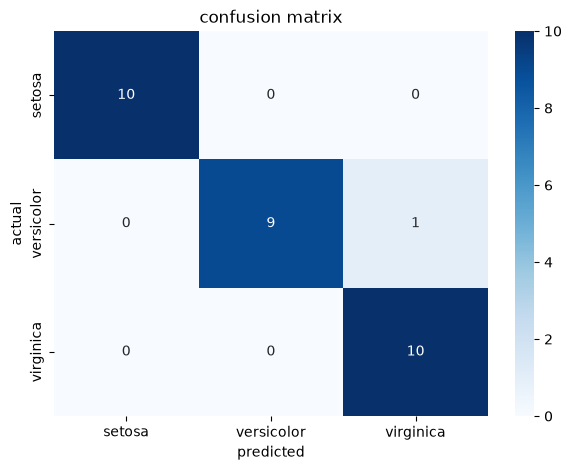

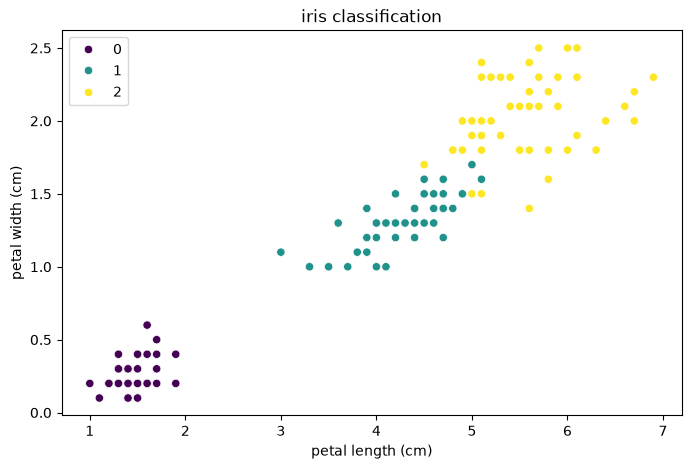


New Prediction:
versicolor

Prediction Probabilities:
[[0.00774324 0.79491973 0.19733703]]

Program Completed


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

iri = load_iris()

dat = pd.DataFrame(
    iri.data,
    columns=iri.feature_names
)

x = dat[
    [
        'sepal length (cm)',
        'sepal width (cm)',
        'petal length (cm)',
        'petal width (cm)'
    ]
]

y = iri.target

xtr, xte, ytr, yte = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

mod = LogisticRegression(max_iter=200)

mod.fit(xtr, ytr)

ypred = mod.predict(xte)

prob = mod.predict_proba(xte)

acc = accuracy_score(yte, ypred)

cm = confusion_matrix(yte, ypred)

print("\nAccuracy:", acc)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(yte, ypred))

res = pd.DataFrame({
    'actual': yte,
    'predicted': ypred
})

print("\nActual vs Predicted:")
print(res.head(10))

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iri.target_names,
    yticklabels=iri.target_names
)

plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('confusion matrix')
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dat,
    x='petal length (cm)',
    y='petal width (cm)',
    hue=y,
    palette='viridis'
)

plt.title('iris classification')
plt.show()

new = pd.DataFrame({
    'sepal length (cm)': [6.0],
    'sepal width (cm)': [3.0],
    'petal length (cm)': [4.5],
    'petal width (cm)': [1.5]
})

pre = mod.predict(new)

print("\nNew Prediction:")
print(iri.target_names[pre[0]])

print("\nPrediction Probabilities:")
print(mod.predict_proba(new))

print("\nProgram Completed")
